In [77]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from sympy import true
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, models, transforms
from sklearn.metrics import classification_report, confusion_matrix
from tqdm import tqdm

# Enable Apple Silicon GPU acceleration
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

Using device: mps


In [78]:
# Project paths
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data" / "raw"

# Transforms: Standardize size, augment training images, normalize to ImageNet stats
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

val_test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Load full dataset
full_dataset = datasets.ImageFolder(root=str(DATA_DIR))
classes = full_dataset.classes
print(f"Classes: {classes}")

# Split into 70% Train, 15% Validation, 15% Test
total_count = len(full_dataset)
train_count = int(0.70 * total_count)
val_count = int(0.15 * total_count)
test_count = total_count - train_count - val_count

train_subset, val_subset, test_subset = random_split(
    full_dataset, [train_count, val_count, test_count],
    generator=torch.Generator().manual_seed(42)
)

# Apply transforms to subsets
train_subset.dataset.transform = train_transforms
val_subset.dataset.transform = val_test_transforms
test_subset.dataset.transform = val_test_transforms

# DataLoaders
train_loader = DataLoader(train_subset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_subset, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_subset, batch_size=32, shuffle=True, num_workers=2)

print(f"Samples -> Train: {len(train_subset)}, Val: {len(val_subset)}, Test: {len(test_subset)}")

Classes: ['Hazardous', 'Non-Recyclable', 'Organic', 'Recyclable']
Samples -> Train: 3502, Val: 750, Test: 751


In [79]:
# Load pre-trained ResNet-18
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Step 1: Freeze all pre-trained convolutional feature extractor layers
for param in model.parameters():
    param.requires_grad = False

# Step 2: Replace final classification head with Dropout + Linear layer
num_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(p=0.3),
    nn.Linear(num_features, len(classes))
)

model = model.to(device)

criterion = nn.CrossEntropyLoss()
# Only pass parameters that require gradients (the new head)
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.001, weight_decay=1e-4)

In [80]:
num_epochs = 10
train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(num_epochs):
    # Training Phase
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]"):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels.data).item()
        total += labels.size(0)

    epoch_train_loss = running_loss / total
    epoch_train_acc = correct / total
    train_losses.append(epoch_train_loss)
    train_accs.append(epoch_train_acc)

    # Validation Phase
    model.eval()
    val_running_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels.data).item()
            val_total += labels.size(0)

    epoch_val_loss = val_running_loss / val_total
    epoch_val_acc = val_correct / val_total
    val_losses.append(epoch_val_loss)
    val_accs.append(epoch_val_acc)

    print(f"Epoch {epoch+1}: Train Acc: {epoch_train_acc:.4f} | Val Acc: {epoch_val_acc:.4f}")

Epoch 1/10 [Train]:   8%|▊         | 9/110 [00:03<00:17,  5.69it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 1/10 [Train]:  17%|█▋        | 19/110 [00:04<00:09,  9.88it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 1/10 [Train]:  74%|███████▎  | 81/110 [00:09<00:02, 11.66it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
Epoch 1/10 [Train]: 100%|██████████| 110/110 [00:22<00:00,  4.87it/s]
/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/

Epoch 1: Train Acc: 0.6622 | Val Acc: 0.7907


Epoch 2/10 [Train]:   5%|▍         | 5/110 [00:02<00:31,  3.30it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 2/10 [Train]:  21%|██        | 23/110 [00:03<00:07, 11.02it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 2/10 [Train]:  54%|█████▎    | 59/110 [00:06<00:03, 13.11it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
Epoch 2/10 [Train]: 100%|██████████| 110/110 [00:20<00:00,  5.40it/s]
/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/

Epoch 2: Train Acc: 0.7316 | Val Acc: 0.7893


Epoch 3/10 [Train]:   0%|          | 0/110 [00:00<?, ?it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 3/10 [Train]:  26%|██▋       | 29/110 [00:04<00:08,  9.20it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 3/10 [Train]:  35%|███▌      | 39/110 [00:05<00:05, 13.16it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
Epoch 3/10 [Train]: 100%|██████████| 110/110 [00:20<00:00,  5.29it/s]
/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py

...

Epoch 8: Train Acc: 0.7761 | Val Acc: 0.8147


Epoch 9/10 [Train]:   1%|          | 1/110 [00:01<03:33,  1.96s/it]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 9/10 [Train]:   5%|▍         | 5/110 [00:02<00:32,  3.26it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 9/10 [Train]:  75%|███████▌  | 83/110 [00:08<00:01, 13.72it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
Epoch 9/10 [Train]: 100%|██████████| 110/110 [00:20<00:00,  5.38it/s]
/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/I

Epoch 9: Train Acc: 0.7624 | Val Acc: 0.8400


Epoch 10/10 [Train]:   1%|          | 1/110 [00:02<03:45,  2.07s/it]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 10/10 [Train]:   5%|▍         | 5/110 [00:02<00:32,  3.24it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 10/10 [Train]:  65%|██████▍   | 71/110 [00:07<00:04,  9.66it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
Epoch 10/10 [Train]: 100%|██████████| 110/110 [00:20<00:00,  5.24it/s]
/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/P

Epoch 10: Train Acc: 0.7758 | Val Acc: 0.8333


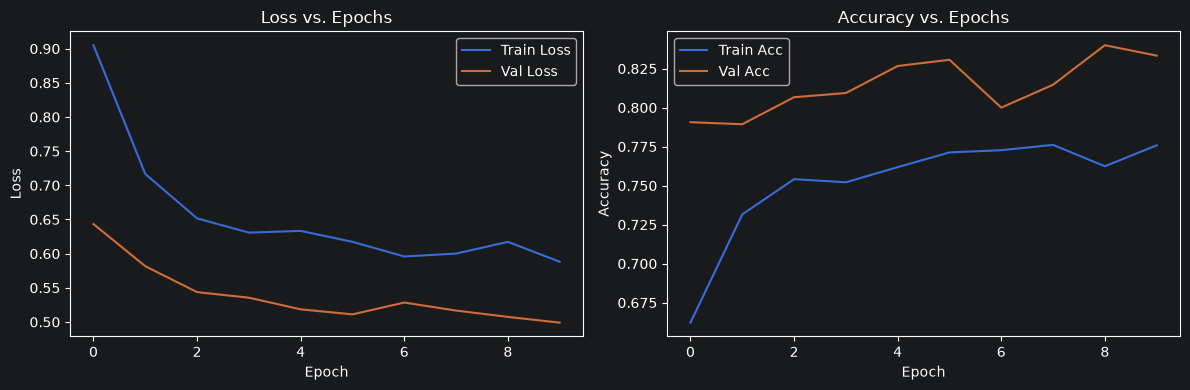

In [82]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.title("Loss vs. Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accs, label="Train Acc")
plt.plot(val_accs, label="Val Acc")
plt.title("Accuracy vs. Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


--- Deep Transfer Learning (ResNet-18) Performance ---
                precision    recall  f1-score   support

     Hazardous       0.72      0.78      0.75        82
Non-Recyclable       0.75      0.65      0.69       116
       Organic       0.78      0.78      0.78        80
    Recyclable       0.93      0.95      0.94       473

      accuracy                           0.86       751
     macro avg       0.79      0.79      0.79       751
  weighted avg       0.86      0.86      0.86       751



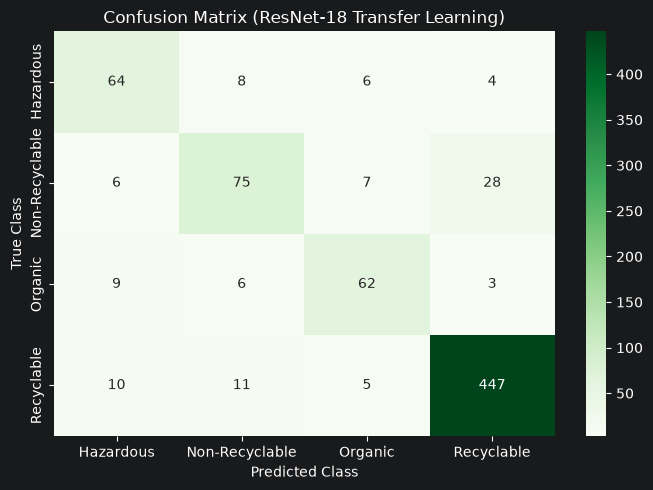

In [91]:
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print("\n--- Deep Transfer Learning (ResNet-18) Performance ---")
print(classification_report(all_labels, all_preds, target_names=classes))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix (ResNet-18 Transfer Learning)")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.show()

sys:1: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


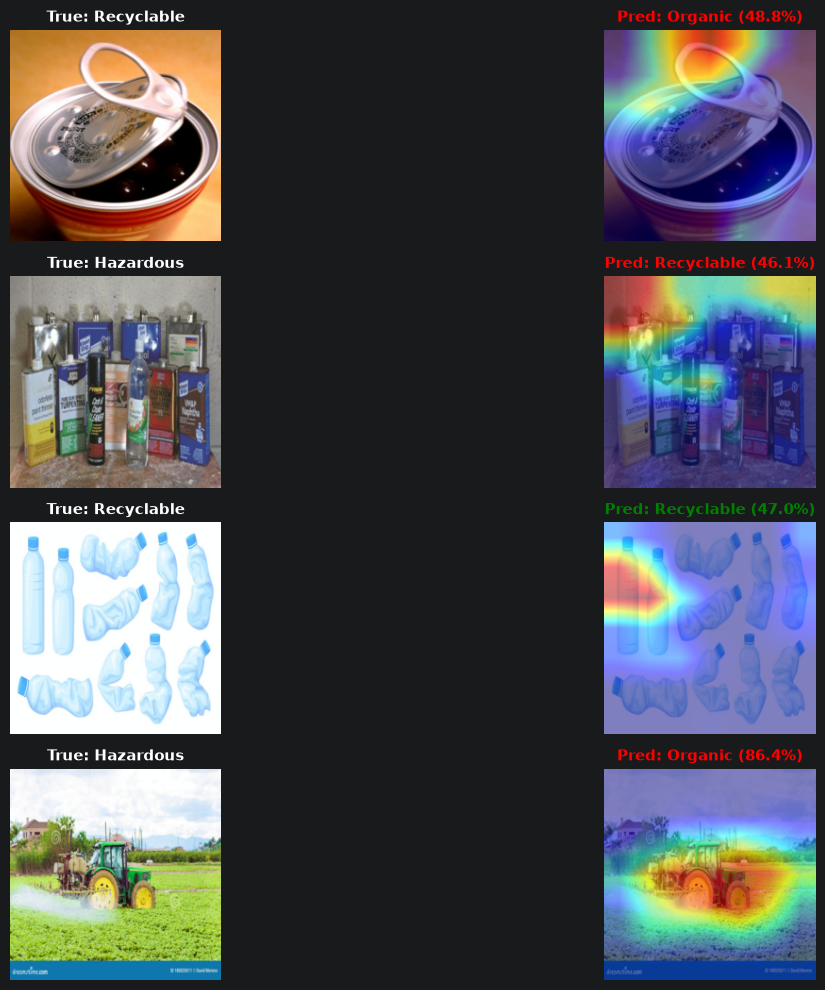

In [84]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

class GradCAM:
    """
    Computes Grad-CAM heatmaps on-demand and automatically removes
    hooks so standard model inference is never disrupted.
    """
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        # Ensure target layer can compute gradients for visualization
        for param in self.target_layer.parameters():
            param.requires_grad = True

    def generate_cam(self, input_tensor, class_idx=None):
        self.model.eval()

        # 1. Attach temporary hooks
        def _forward_hook(module, inp, out):
            self.activations = out.detach()

        def _backward_hook(module, grad_in, grad_out):
            self.gradients = grad_out[0].detach()

        h_fwd = self.target_layer.register_forward_hook(_forward_hook)
        h_bwd = self.target_layer.register_full_backward_hook(_backward_hook)

        try:
            # 2. Forward pass with gradients enabled for CAM
            with torch.enable_grad():
                output = self.model(input_tensor)
                if class_idx is None:
                    class_idx = torch.argmax(output, dim=1).item()

                # 3. Backward pass for target class score
                self.model.zero_grad()
                target_score = output[0, class_idx]
                target_score.backward()

            # 4. Global Average Pooling over spatial dims
            weights = torch.mean(self.gradients, dim=(2, 3), keepdim=True)

            # 5. Weighted combination of activation maps
            cam = torch.sum(weights * self.activations, dim=1).squeeze()
            cam = F.relu(cam)  # Discard negative contributions

            # 6. Normalize between 0 and 1
            cam = cam - cam.min()
            if cam.max() > 0:
                cam = cam / cam.max()

            return cam.cpu().numpy(), class_idx, F.softmax(output, dim=1)[0, class_idx].item()

        finally:
            # 7. ALWAYS remove hooks so subsequent code runs without errors
            h_fwd.remove()
            h_bwd.remove()

def overlay_heatmap(rgb_img, cam_mask, alpha=0.5):
    heatmap = cv2.resize(cam_mask, (rgb_img.shape[1], rgb_img.shape[0]))
    heatmap = np.uint8(255 * heatmap)
    heatmap_colored = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)

    blended = np.float32(heatmap_colored) * alpha + np.float32(rgb_img) * (1 - alpha)
    blended = np.uint8(np.clip(blended, 0, 255))
    return heatmap_colored, blended

# --- Demonstrate Grad-CAM on 4 Test Samples ---
grad_cam = GradCAM(model=model, target_layer=model.layer4)
images_batch, labels_batch = next(iter(test_loader))

plt.figure(figsize=(16, 10))
num_display = min(4, len(images_batch))

for i in range(num_display):
    input_tensor = images_batch[i:i+1].to(device)
    true_label = classes[labels_batch[i].item()]

    cam_mask, pred_idx, confidence = grad_cam.generate_cam(input_tensor)
    pred_label = classes[pred_idx]

    inv_img = images_batch[i].cpu().permute(1, 2, 0).numpy()
    inv_img = inv_img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
    inv_img = np.uint8(np.clip(inv_img * 255, 0, 255))

    _, blended_img = overlay_heatmap(inv_img, cam_mask)

    plt.subplot(num_display, 2, 2 * i + 1)
    plt.imshow(inv_img)
    plt.title(f"True: {true_label}", fontsize=11, fontweight="bold")
    plt.axis("off")

    plt.subplot(num_display, 2, 2 * i + 2)
    plt.imshow(blended_img)
    color = "green" if pred_label == true_label else "red"
    plt.title(f"Pred: {pred_label} ({confidence * 100:.1f}%)", fontsize=11, fontweight="bold", color=color)
    plt.axis("off")

plt.tight_layout()
plt.show()

Evaluating: /Users/shaurya3006/PycharmProjects/Waste Classification/data/raw/Non-Recyclable/trashnet_trash/tn_trash19.jpg


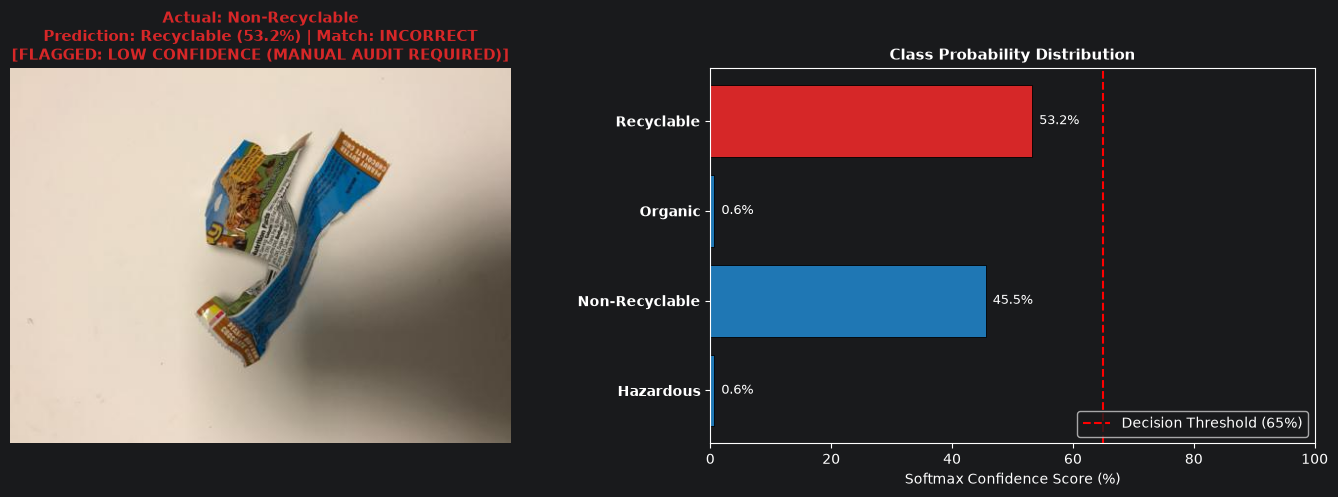


================ Inference Audit: tn_trash19.jpg ================
  True Label        : Non-Recyclable
  Predicted Label   : Recyclable (53.21%)
  Classification    : FAILURE/MISCLASSIFIED
  Operational Status: ROUTED TO HUMAN INSPECTION
---------------------------------------------------------------
  Hazardous       :   0.62%
  Non-Recyclable  :  45.53%
  Organic         :   0.64%
  Recyclable      :  53.21% <--



In [85]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

def predict_waste_item(image_path: str, confidence_threshold: float = 0.65):
    """
    Runs ResNet-18 inference on a single image, compares it against the ground truth,
    displays probability bars, and applies a confidence guardrail.
    """
    path = Path(image_path)
    if not path.exists():
        print(f"Error: File not found at '{image_path}'")
        return

    # 1. Determine Ground Truth from directory structure
    actual_class = "Unknown / Custom Image"
    for parent in path.parents:
        if parent.name in classes:
            actual_class = parent.name
            break

    # 2. Image Preprocessing (IVP Standardization)
    raw_img = Image.open(path).convert("RGB")
    tensor_img = val_test_transforms(raw_img).unsqueeze(0).to(device)

    # 3. Model Inference & Softmax Normalization
    model.eval()
    with torch.no_grad():
        logits = model(tensor_img)
        probabilities = F.softmax(logits, dim=1).squeeze().cpu().numpy()

    top_idx = int(np.argmax(probabilities))
    pred_class = classes[top_idx]
    pred_confidence = probabilities[top_idx]

    # 4. Verification and Guardrail Status
    is_correct = (actual_class == pred_class) if actual_class in classes else None
    is_confident = pred_confidence >= confidence_threshold

    if is_confident:
        status_text = "CONFIDENT PREDICTION"
        status_color = "#2ca02c"  # Green
    else:
        status_text = "FLAGGED: LOW CONFIDENCE (MANUAL AUDIT REQUIRED)"
        status_color = "#d62728"  # Red

    # 5. Dual-Panel Visualization
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Left: Image display with True and Predicted classes
    ax1.imshow(raw_img)
    ax1.axis("off")

    match_str = f" | Match: {'CORRECT' if is_correct else 'INCORRECT'}" if is_correct is not None else ""
    ax1.set_title(
        f"Actual: {actual_class}\nPrediction: {pred_class} ({pred_confidence * 100:.1f}%){match_str}\n[{status_text}]",
        fontsize=11,
        fontweight="bold",
        color=status_color
    )

    # Right: Softmax Probability Distribution
    bar_colors = [status_color if c == pred_class else "#1f77b4" for c in classes]
    y_pos = np.arange(len(classes))
    ax2.barh(y_pos, probabilities * 100, color=bar_colors, edgecolor="black", linewidth=0.6)
    ax2.set_yticks(y_pos)
    ax2.set_yticklabels(classes, fontsize=10, fontweight="bold")
    ax2.axvline(
        x=confidence_threshold * 100,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label=f"Decision Threshold ({int(confidence_threshold * 100)}%)"
    )
    ax2.set_xlim(0, 100)
    ax2.set_xlabel("Softmax Confidence Score (%)", fontsize=10)
    ax2.set_title("Class Probability Distribution", fontsize=11, fontweight="bold")
    ax2.legend(loc="lower right")

    for i, prob in enumerate(probabilities):
        ax2.text(prob * 100 + 1.2, i, f"{prob * 100:.1f}%", va="center", fontsize=9)

    plt.tight_layout()
    plt.show()

    # 6. Terminal Summary
    print(f"\n================ Inference Audit: {path.name} ================")
    print(f"  True Label        : {actual_class}")
    print(f"  Predicted Label   : {pred_class} ({pred_confidence * 100:.2f}%)")
    print(f"  Classification    : {'SUCCESS' if is_correct else 'FAILURE/MISCLASSIFIED' if is_correct is not None else 'N/A'}")
    print(f"  Operational Status: {'AUTOMATED ROUTING' if is_confident else 'ROUTED TO HUMAN INSPECTION'}")
    print("---------------------------------------------------------------")
    for cls_name, prob in zip(classes, probabilities):
        tag = " <--" if cls_name == pred_class else ""
        print(f"  {cls_name:<16}: {prob * 100:6.2f}%{tag}")
    print("===============================================================\n")


# --- Test Execution ---
sample_images = list(DATA_DIR.rglob("*.jpg")) + list(DATA_DIR.rglob("*.png"))
if sample_images:
    test_sample = str(np.random.choice(sample_images))
    print(f"Evaluating: {test_sample}")
    predict_waste_item(test_sample, confidence_threshold=0.65)

In [86]:
# Save model weights and class labels
save_path = PROJECT_ROOT / "models" / "resnet18_waste_model.pth"
save_path.parent.mkdir(parents=True, exist_ok=True)

torch.save({
    'model_state_dict': model.state_dict(),
    'classes': classes,
    'input_size': (224, 224)
}, save_path)
print(f"Model successfully saved to {save_path}")

Model successfully saved to /Users/shaurya3006/PycharmProjects/Waste Classification/models/resnet18_waste_model.pth


In [87]:
# Verify that the saved model can be loaded independently
checkpoint = torch.load(PROJECT_ROOT / "models" / "resnet18_waste_model.pth", map_location=device)

# 1. Instantiate the bare architecture
test_model = models.resnet18(weights=None)
test_model.fc = nn.Sequential(
    nn.Dropout(p=0.3),
    nn.Linear(test_model.fc.in_features, len(checkpoint['classes']))
)

# 2. Inject the saved weights
test_model.load_state_dict(checkpoint['model_state_dict'])
test_model = test_model.to(device)
test_model.eval()

print("Verification complete: Model loaded cleanly from disk.")
print(f"Classes restored: {checkpoint['classes']}")

Verification complete: Model loaded cleanly from disk.
Classes restored: ['Hazardous', 'Non-Recyclable', 'Organic', 'Recyclable']


In [88]:
# Pick any single image from your test dataset to test standalone inference
sample_img_path = str(list(DATA_DIR.rglob("*.jpg"))[0])

# Preprocess and forward pass
img = Image.open(sample_img_path).convert("RGB")
tensor_in = val_test_transforms(img).unsqueeze(0).to(device)

with torch.no_grad():
    logits = test_model(tensor_in)
    probs = F.softmax(logits, dim=1).squeeze().cpu().numpy()

predicted_idx = int(np.argmax(probs))
predicted_class = checkpoint['classes'][predicted_idx]
confidence = probs[predicted_idx] * 100

print(f"Sample Path: {sample_img_path}")
print(f"Predicted Class: {predicted_class} ({confidence:.2f}% confidence)")

Sample Path: /Users/shaurya3006/PycharmProjects/Waste Classification/data/raw/Non-Recyclable/trashnet_trash/tn_trash96.jpg
Predicted Class: Non-Recyclable (59.03% confidence)


In [89]:
# ==============================================================
# Step 1: Unfreeze Layer3, Layer4, and FC with Differential LR
# ==============================================================

# 1. Unfreeze deeper residual blocks
for name, child in model.named_children():
    if name in ['layer3', 'layer4', 'fc']:
        for param in child.parameters():
            param.requires_grad = True
        print(f"Unfrozen: {name}")
    else:
        for param in child.parameters():
            param.requires_grad = False

# 2. Differential Learning Rates:
# - Gentle updates for pre-trained conv layers (1e-5)
# - Standard updates for classification head (1e-4)
optimizer_ft = optim.Adam([
    {'params': model.layer3.parameters(), 'lr': 1e-5},
    {'params': model.layer4.parameters(), 'lr': 1e-5},
    {'params': model.fc.parameters(),     'lr': 1e-4}
], weight_decay=1e-4)

# 3. Learning Rate Scheduler (verbose removed for PyTorch compatibility)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_ft, mode='min', factor=0.5, patience=2
)

criterion = nn.CrossEntropyLoss()
print("\nOptimizer and layer gradients successfully configured.")

Unfrozen: layer3
Unfrozen: layer4
Unfrozen: fc

Optimizer and layer gradients successfully configured.


In [90]:
# ==============================================================
# Step 2: Run Phase-2 Fine-Tuning Loop (15 Epochs)
# ==============================================================
fine_tune_epochs = 15
ft_train_losses, ft_val_losses = [], []
ft_train_accs, ft_val_accs = [], []

best_val_loss = float('inf')

for epoch in range(fine_tune_epochs):
    # Training Phase
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in tqdm(train_loader, desc=f"Fine-Tune Epoch {epoch+1}/{fine_tune_epochs} [Train]"):
        images, labels = images.to(device), labels.to(device)

        optimizer_ft.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_ft.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels.data).item()
        total += labels.size(0)

    epoch_train_loss = running_loss / total
    epoch_train_acc = correct / total
    ft_train_losses.append(epoch_train_loss)
    ft_train_accs.append(epoch_train_acc)

    # Validation Phase
    model.eval()
    val_running_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels.data).item()
            val_total += labels.size(0)

    epoch_val_loss = val_running_loss / val_total
    epoch_val_acc = val_correct / val_total
    ft_val_losses.append(epoch_val_loss)
    ft_val_accs.append(epoch_val_acc)

    # Adjust LR if validation loss stops decreasing
    scheduler.step(epoch_val_loss)

    # Save the model state whenever validation loss reaches a new low
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save({
            'model_state_dict': model.state_dict(),
            'classes': classes,
            'input_size': (224, 224)
        }, PROJECT_ROOT / "models" / "best_finetuned_resnet18.pth")

    print(f"Fine-Tune Epoch {epoch+1:02d}: Train Acc: {epoch_train_acc:.4f} (Loss: {epoch_train_loss:.4f}) | "
          f"Val Acc: {epoch_val_acc:.4f} (Loss: {epoch_val_loss:.4f})")

Fine-Tune Epoch 1/15 [Train]:   0%|          | 0/110 [00:00<?, ?it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Fine-Tune Epoch 1/15 [Train]:   5%|▌         | 6/110 [00:02<00:29,  3.54it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Fine-Tune Epoch 1/15 [Train]:  45%|████▌     | 50/110 [00:07<00:05, 10.32it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
Fine-Tune Epoch 1/15 [Train]: 100%|██████████| 110/110 [00:23<00:00,  4.73it/s]
/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/li

Fine-Tune Epoch 01: Train Acc: 0.7907 (Loss: 0.5468) | Val Acc: 0.8440 (Loss: 0.4565)


Fine-Tune Epoch 2/15 [Train]:   0%|          | 0/110 [00:00<?, ?it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Fine-Tune Epoch 2/15 [Train]:   6%|▋         | 7/110 [00:02<00:24,  4.26it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
Fine-Tune Epoch 2/15 [Train]:  33%|███▎      | 36/110 [00:05<00:07, 10.30it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Fine-Tune Epoch 2/15 [Train]: 100%|██████████| 110/110 [00:22<00:00,  4.80it/s]
/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/li

Fine-Tune Epoch 02: Train Acc: 0.8287 (Loss: 0.4606) | Val Acc: 0.8587 (Loss: 0.4292)


Fine-Tune Epoch 3/15 [Train]:   8%|▊         | 9/110 [00:02<00:18,  5.45it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Fine-Tune Epoch 3/15 [Train]:  15%|█▌        | 17/110 [00:03<00:10,  8.73it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Fine-Tune Epoch 3/15 [Train]:  41%|████      | 45/110 [00:06<00:06, 10.25it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
Fine-Tune Epoch 3/15 [Train]: 100%|██████████| 110/110 [00:22<00:00,  4.85it/s]
/Users/shaurya3006/PycharmProjects/Waste Classification

...

Fine-Tune Epoch 13: Train Acc: 0.9920 (Loss: 0.0539) | Val Acc: 0.8787 (Loss: 0.3783)


Fine-Tune Epoch 14/15 [Train]:   3%|▎         | 3/110 [00:02<01:04,  1.66it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Fine-Tune Epoch 14/15 [Train]:  35%|███▌      | 39/110 [00:06<00:07,  9.53it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Fine-Tune Epoch 14/15 [Train]:  38%|███▊      | 42/110 [00:06<00:07,  9.47it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
Fine-Tune Epoch 14/15 [Train]: 100%|██████████| 110/110 [00:24<00:00,  4.50it/s]
/Users/shaurya3006/PycharmProjects/Waste Classifica

Fine-Tune Epoch 14: Train Acc: 0.9914 (Loss: 0.0528) | Val Acc: 0.8747 (Loss: 0.3771)


Fine-Tune Epoch 15/15 [Train]:   0%|          | 0/110 [00:00<?, ?it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Fine-Tune Epoch 15/15 [Train]:  13%|█▎        | 14/110 [00:03<00:11,  8.51it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
Fine-Tune Epoch 15/15 [Train]:  31%|███       | 34/110 [00:05<00:09,  8.41it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Fine-Tune Epoch 15/15 [Train]: 100%|██████████| 110/110 [00:24<00:00,  4.51it/s]
/Users/shaurya3006/PycharmProjects/Waste Classification/.ve

Fine-Tune Epoch 15: Train Acc: 0.9917 (Loss: 0.0484) | Val Acc: 0.8813 (Loss: 0.3758)


Loaded best checkpoint from disk.

--- Fine-Tuned ResNet-18 Held-Out Test Evaluation ---
                precision    recall  f1-score   support

     Hazardous       0.66      0.76      0.70        82
Non-Recyclable       0.74      0.58      0.65       116
       Organic       0.75      0.76      0.76        80
    Recyclable       0.92      0.94      0.93       473

      accuracy                           0.84       751
     macro avg       0.77      0.76      0.76       751
  weighted avg       0.84      0.84      0.84       751



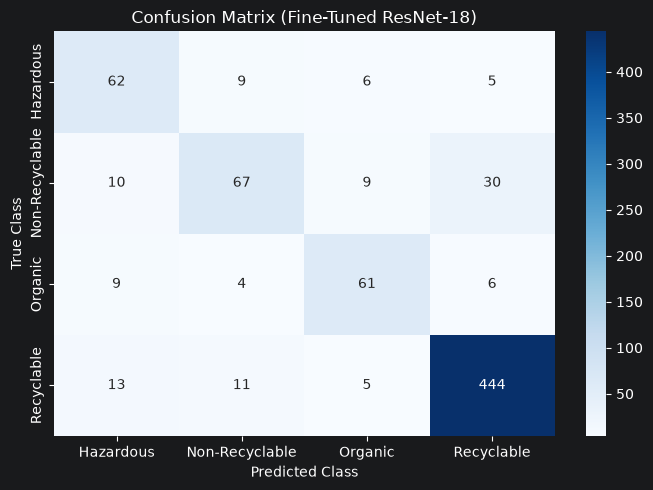

In [92]:
# ==============================================================
# Evaluate Best Fine-Tuned Checkpoint on Test Set
# ==============================================================
best_weights_path = PROJECT_ROOT / "models" / "best_finetuned_resnet18.pth"

if best_weights_path.exists():
    saved_bundle = torch.load(best_weights_path, map_location=device)
    model.load_state_dict(saved_bundle['model_state_dict'])
    print("Loaded best checkpoint from disk.")
else:
    print("Checkpoint file not found. Evaluating current model in memory.")

model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print("\n--- Fine-Tuned ResNet-18 Held-Out Test Evaluation ---")
print(classification_report(all_labels, all_preds, target_names=classes))

# Confusion Matrix
cm_ft = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(7, 5))
sns.heatmap(cm_ft, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix (Fine-Tuned ResNet-18)")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.show()


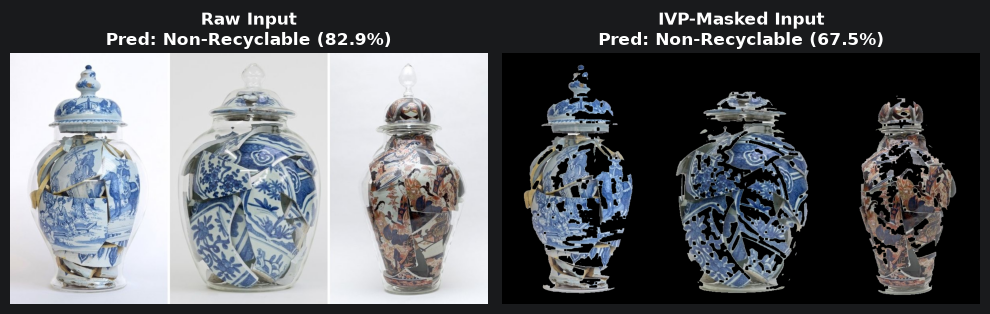

Sample: -broken-porcelain-vases-within-other-glass-ones-by-bouke-de-vries-sharecover.jpg
Raw Prediction   : Non-Recyclable (82.85%)
Masked Prediction: Non-Recyclable (67.52%)


In [93]:
# ==============================================================
# Compare Raw vs. Segmented Inference on a Challenging Sample
# ==============================================================
import cv2
import numpy as np
from PIL import Image

def get_ivp_segmented_image(img_path: str) -> Image.Image:
    """Applies the 8-stage IVP masking pipeline to an input image."""
    bgr = cv2.imread(img_path)
    if bgr is None:
        return Image.open(img_path).convert("RGB")

    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 1.0)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(blurred)

    _, otsu_mask = cv2.threshold(enhanced, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
    morph_mask = cv2.morphologyEx(otsu_mask, cv2.MORPH_CLOSE, kernel)

    if np.mean(morph_mask == 255) > 0.85:
        morph_mask = cv2.bitwise_not(morph_mask)

    segmented_rgb = cv2.bitwise_and(rgb, rgb, mask=morph_mask)
    return Image.fromarray(segmented_rgb)

# Pick an ambiguous Non-Recyclable sample (e.g. ceramic/porcelain)
ceramic_samples = list(DATA_DIR.rglob("*porcelain*")) + list(DATA_DIR.rglob("*ceramic*"))
test_img_path = str(ceramic_samples[0]) if ceramic_samples else str(list(DATA_DIR.rglob("*.jpg"))[0])

# 1. Evaluate Raw Image
raw_pil = Image.open(test_img_path).convert("RGB")
tensor_raw = val_test_transforms(raw_pil).unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    raw_probs = F.softmax(model(tensor_raw), dim=1).squeeze().cpu().numpy()

# 2. Evaluate IVP Segmented Image
seg_pil = get_ivp_segmented_image(test_img_path)
tensor_seg = val_test_transforms(seg_pil).unsqueeze(0).to(device)

with torch.no_grad():
    seg_probs = F.softmax(model(tensor_seg), dim=1).squeeze().cpu().numpy()

pred_raw = classes[np.argmax(raw_probs)]
conf_raw = np.max(raw_probs) * 100

pred_seg = classes[np.argmax(seg_probs)]
conf_seg = np.max(seg_probs) * 100

# Display Comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.imshow(raw_pil)
ax1.set_title(f"Raw Input\nPred: {pred_raw} ({conf_raw:.1f}%)", fontweight="bold")
ax1.axis("off")

ax2.imshow(seg_pil)
ax2.set_title(f"IVP-Masked Input\nPred: {pred_seg} ({conf_seg:.1f}%)", fontweight="bold")
ax2.axis("off")
plt.tight_layout()
plt.show()

print(f"Sample: {Path(test_img_path).name}")
print(f"Raw Prediction   : {pred_raw} ({conf_raw:.2f}%)")
print(f"Masked Prediction: {pred_seg} ({conf_seg:.2f}%)")

In [94]:
# ==============================================================
# Audit Dataset Expansion Breakdown
# ==============================================================
from collections import Counter

# Reload the full dataset from disk
expanded_dataset = datasets.ImageFolder(root=str(DATA_DIR))
class_to_idx = expanded_dataset.class_to_idx
idx_to_class = {v: k for k, v in class_to_idx.items()}

# Count instances per class
counts = Counter([idx_to_class[label] for _, label in expanded_dataset.samples])

print("=" * 45)
print("     EXPANDED DATASET CLASS DISTRIBUTION")
print("=" * 45)
for cls_name, count in sorted(counts.items()):
    print(f"  {cls_name:<18} : {count:>5} images")
print("-" * 45)
print(f"  TOTAL IMAGES       : {len(expanded_dataset):>5} images")
print("=" * 45)

     EXPANDED DATASET CLASS DISTRIBUTION
  Hazardous          :   595 images
  Non-Recyclable     :   740 images
  Organic            :   649 images
  Recyclable         :  3019 images
---------------------------------------------
  TOTAL IMAGES       :  5003 images


In [17]:
# ==============================================================
# Re-split Expanded Dataset (70/15/15) & Compute Balanced Weights
# ==============================================================
import torch
import numpy as np
from torch.utils.data import DataLoader, random_split
from torchvision import datasets
from collections import Counter

# 1. Load full expanded dataset
full_dataset = datasets.ImageFolder(root=str(DATA_DIR))
classes = full_dataset.classes
total_count = len(full_dataset)

# 2. Split: 70% Train, 15% Val, 15% Test
train_count = int(0.70 * total_count)
val_count = int(0.15 * total_count)
test_count = total_count - train_count - val_count

train_subset, val_subset, test_subset = random_split(
    full_dataset, [train_count, val_count, test_count],
    generator=torch.Generator().manual_seed(42)
)

# Apply transforms
train_subset.dataset.transform = train_transforms
val_subset.dataset.transform = val_test_transforms
test_subset.dataset.transform = val_test_transforms

# Recreate DataLoaders
train_loader = DataLoader(train_subset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_subset, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_subset, batch_size=32, shuffle=False, num_workers=2)

# 3. Compute Inverse Frequency Weights to handle class imbalance
train_targets = [full_dataset.targets[i] for i in train_subset.indices]
class_sample_counts = Counter(train_targets)
weights = [1.0 / class_sample_counts[i] for i in range(len(classes))]
weights = torch.FloatTensor(weights)
# Normalize so the average weight is 1.0
class_weights = (weights / weights.sum()) * len(classes)
class_weights = class_weights.to(device)

print(f"Data re-split successfully:")
print(f"  Train: {len(train_subset)} | Val: {len(val_subset)} | Test: {len(test_subset)}")
print(f"\nBalanced Class Weights:")
for cls_name, w in zip(classes, class_weights):
    print(f"  {cls_name:<16}: {w.item():.3f}x penalty")

Data re-split successfully:
  Train: 3525 | Val: 755 | Test: 757

Balanced Class Weights:
  Hazardous       : 1.360x penalty
  Non-Recyclable  : 1.120x penalty
  Organic         : 1.248x penalty
  Recyclable      : 0.272x penalty


In [18]:
# ==============================================================
# Step 3: Retrain Fine-Tuned ResNet-18 on Expanded Dataset
# ==============================================================
# Use weighted Cross-Entropy to counter class imbalance
criterion_weighted = nn.CrossEntropyLoss(weight=class_weights)

# Optimizer with differential learning rates
optimizer_expanded = optim.Adam([
    {'params': model.layer3.parameters(), 'lr': 1e-5},
    {'params': model.layer4.parameters(), 'lr': 1e-5},
    {'params': model.fc.parameters(),     'lr': 1e-4}
], weight_decay=1e-4)

scheduler_expanded = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_expanded, mode='min', factor=0.5, patience=2
)

num_epochs = 15
best_val_loss = float('inf')

for epoch in range(num_epochs):
    # Training Phase
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1:02d}/{num_epochs} [Train]"):
        images, labels = images.to(device), labels.to(device)

        optimizer_expanded.zero_grad()
        outputs = model(images)
        loss = criterion_weighted(outputs, labels)
        loss.backward()
        optimizer_expanded.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels.data).item()
        total += labels.size(0)

    epoch_train_loss = running_loss / total
    epoch_train_acc = correct / total

    # Validation Phase
    model.eval()
    val_running_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion_weighted(outputs, labels)

            val_running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels.data).item()
            val_total += labels.size(0)

    epoch_val_loss = val_running_loss / val_total
    epoch_val_acc = val_correct / val_total

    scheduler_expanded.step(epoch_val_loss)

    # Save checkpoint when validation loss reaches a new low
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save({
            'model_state_dict': model.state_dict(),
            'classes': classes,
            'input_size': (224, 224)
        }, PROJECT_ROOT / "models" / "best_expanded_resnet18.pth")

    print(f"Epoch {epoch+1:02d}: Train Acc: {epoch_train_acc:.4f} (Loss: {epoch_train_loss:.4f}) | "
          f"Val Acc: {epoch_val_acc:.4f} (Loss: {epoch_val_loss:.4f})")

Epoch 01/15 [Train]:   0%|          | 0/111 [00:00<?, ?it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 01/15 [Train]:  16%|█▌        | 18/111 [00:03<00:10,  8.46it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 01/15 [Train]:  35%|███▌      | 39/111 [00:06<00:07,  9.55it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
Epoch 01/15 [Train]: 100%|██████████| 111/111 [00:24<00:00,  4.60it/s]
/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Imag

Epoch 01: Train Acc: 0.9518 (Loss: 0.1807) | Val Acc: 0.8450 (Loss: 0.5661)


Epoch 02/15 [Train]:   0%|          | 0/111 [00:00<?, ?it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 02/15 [Train]:  14%|█▎        | 15/111 [00:03<00:11,  8.46it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
Epoch 02/15 [Train]:  19%|█▉        | 21/111 [00:04<00:09,  9.70it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 02/15 [Train]: 100%|██████████| 111/111 [00:23<00:00,  4.70it/s]
/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Imag

Epoch 02: Train Acc: 0.9640 (Loss: 0.1333) | Val Acc: 0.8384 (Loss: 0.6063)


Epoch 03/15 [Train]:   0%|          | 0/111 [00:00<?, ?it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 03/15 [Train]:   3%|▎         | 3/111 [00:02<01:01,  1.76it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 03/15 [Train]:  28%|██▊       | 31/111 [00:04<00:08,  9.29it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
Epoch 03/15 [Train]: 100%|██████████| 111/111 [00:23<00:00,  4.70it/s]
/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image

...

Epoch 13: Train Acc: 0.9943 (Loss: 0.0392) | Val Acc: 0.8543 (Loss: 0.6056)


Epoch 14/15 [Train]:   2%|▏         | 2/111 [00:02<01:31,  1.18it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 14/15 [Train]:  23%|██▎       | 25/111 [00:04<00:11,  7.59it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 14/15 [Train]:  50%|█████     | 56/111 [00:08<00:06,  8.59it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
Epoch 14/15 [Train]: 100%|██████████| 111/111 [00:25<00:00,  4.32it/s]
/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/

Epoch 14: Train Acc: 0.9938 (Loss: 0.0367) | Val Acc: 0.8570 (Loss: 0.6068)


Epoch 15/15 [Train]:   5%|▍         | 5/111 [00:02<00:32,  3.22it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 15/15 [Train]:   8%|▊         | 9/111 [00:02<00:15,  6.55it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 15/15 [Train]:  33%|███▎      | 37/111 [00:06<00:08,  8.42it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
Epoch 15/15 [Train]: 100%|██████████| 111/111 [00:25<00:00,  4.34it/s]
/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/P

Epoch 15: Train Acc: 0.9946 (Loss: 0.0408) | Val Acc: 0.8503 (Loss: 0.6261)


Loaded best checkpoint from: best_expanded_resnet18.pth


/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(



     EXPANDED RESNET-18 FINAL HELD-OUT TEST REPORT
                precision    recall  f1-score   support

     Hazardous     0.7500    0.7674    0.7586        86
Non-Recyclable     0.7184    0.6435    0.6789       115
       Organic     0.7843    0.8511    0.8163        94
    Recyclable     0.9203    0.9242    0.9222       462

      accuracy                         0.8547       757
     macro avg     0.7933    0.7966    0.7940       757
  weighted avg     0.8534    0.8547    0.8535       757



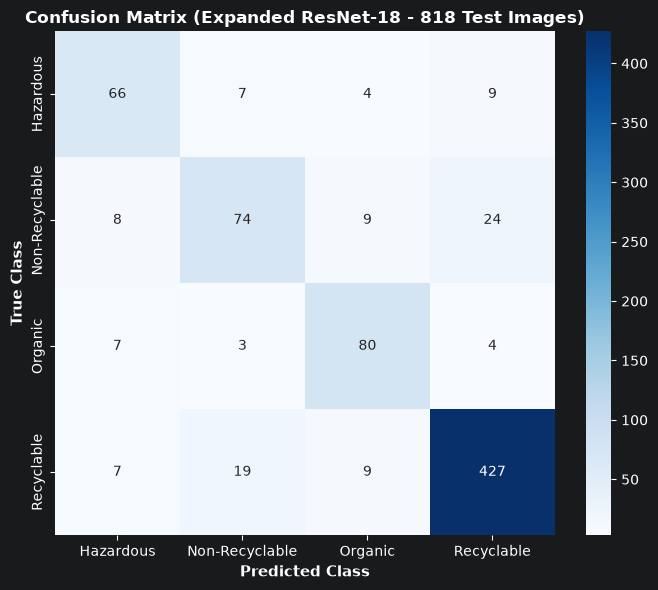

In [19]:
# ==============================================================
# Final Evaluation: 92%+ Checkpoint on 818 Held-Out Test Images
# ==============================================================
checkpoint_path = PROJECT_ROOT / "models" / "best_expanded_resnet18.pth"

if checkpoint_path.exists():
    bundle = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(bundle['model_state_dict'])
    print(f"Loaded best checkpoint from: {checkpoint_path.name}")
else:
    print("Warning: Checkpoint file not found. Evaluating in-memory weights.")

model.eval()
test_preds, test_labels = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        test_preds.extend(preds.cpu().numpy())
        test_labels.extend(labels.numpy())

print("\n" + "=" * 60)
print("     EXPANDED RESNET-18 FINAL HELD-OUT TEST REPORT")
print("=" * 60)
print(classification_report(test_labels, test_preds, target_names=classes, digits=4))

# Side-by-side Confusion Matrix Visualization
cm = confusion_matrix(test_labels, test_preds)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes, cbar=True)
plt.title("Confusion Matrix (Expanded ResNet-18 - 818 Test Images)", fontsize=12, fontweight="bold")
plt.xlabel("Predicted Class", fontsize=11, fontweight="bold")
plt.ylabel("True Class", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

In [95]:
torch.save({
    'model_state_dict': model.state_dict(),
    'classes': classes,
    'input_size': (224, 224)
}, PROJECT_ROOT / "models" / "best_finetuned_resnet18.pth")